## Assignment: Image recognition
- Alumno 1: Alex Sierra Alcalá
- Alumno 2: Roberto Inclán Alfonso
- Alumno 3: Mario Hernández Trillo

The goals of the assignment are:
* Develop proficiency in using Tensorflow/Keras for training Neural Nets (NNs).
* Put into practice the acquired knowledge to optimize the parameters and architecture of a feedforward Neural Net (ffNN), in the context of an image recognition problem.
* Put into practice NNs specially conceived for analysing images. Design and optimize the parameters of a Convolutional Neural Net (CNN) to deal with previous task.
* Train popular architectures from scratch (e.g., GoogLeNet, VGG, ResNet, ...), and compare the results with the ones provided by their pre-trained versions using transfer learning.

Follow the link below to download the classification data set  “xview_recognition”: [https://drive.upm.es/s/2DDPE2zHw5dbM3G](https://drive.upm.es/s/2DDPE2zHw5dbM3G)

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

import keras
# Reproducibility: same seed -> same run, also on GPU (EXP-001)
keras.utils.set_random_seed(1)
tf.config.experimental.enable_op_determinism()

I0000 00:00:1792803967.984796 4106735 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792803969.076295 4106735 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792803973.673762 4106735 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])  # (pt_x, pt_y, pt_x+width, pt_y+height)
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [3]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [4]:
import warnings
import rasterio
import numpy as np

def load_geoimage(filename):
    warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
    src_raster = rasterio.open('./xview_recognition/'+filename, 'r')
    # RasterIO to OpenCV (see inconsistencies between libjpeg and libjpeg-turbo)
    input_type = src_raster.profile['dtype']
    input_channels = src_raster.count
    img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
    for band in range(input_channels):
        img[:, :, band] = src_raster.read(band+1)
    return img

#### Training
Design and train a ffNN to deal with the “xview_recognition” classification task.

In [5]:
import json

# Load database
json_file = './xview_recognition/xview_ann_train.json'
with open(json_file) as ifs:
    json_data = json.load(ifs)
ifs.close()

In [6]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


**Split.** Stratified by class with a fixed seed, so that the small classes (Helipad: 111 images) keep exactly
their 10 % in validation and runs are comparable (EXP-001).

In [7]:
from sklearn.model_selection import train_test_split

# Stratified split: every class keeps its 10 % in validation (EXP-001)
labels = np.array([list(categories.values()).index(ann.objects[0].category) for ann in anns])
idx_train, idx_valid = train_test_split(np.arange(len(anns)), test_size=0.1, random_state=1, shuffle=True, stratify=labels)
anns_train, anns_valid = [anns[i] for i in idx_train], [anns[i] for i in idx_valid]
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [8]:
from xview_data import load_cache

# Image cache (CHG-007): every TIF is read once with load_geoimage, downsampled by area averaging to RES x RES and
# kept as uint8 in cache/train_<RES>.npy; the order is the one of the annotations file (= the order of `anns`).
# 112 x 112 for the CNN (EXP-031: with 5 blocks it beats 32 and 64 px; the 16 x 16 of the ffNN was only good for a ffNN).
RES = 112
x_all = load_cache('train', RES)
y_all = labels
print(x_all.shape, x_all.dtype)

(18746, 112, 112, 3) uint8


**Model (delivery 3).** Own CNN, `Input(112×112×3) → Rescaling(1/255) → 5 × block → GlobalAveragePooling → Dense(13, softmax)`,
where each block is `2 × [Conv 3×3 ('same', no bias, He init) → BatchNorm → LeakyReLU(0.3)] → MaxPool 2×2` with 32, 64,
128, 256 and 512 filters (4.7 M parameters).
- Convolutions instead of dense layers (EXP-029): local, shared weights see the objects wherever they are in the crop.
  The ffNN needed 16×16 inputs; the CNN uses the detail of 112×112 (EXP-030, EXP-031: with 5 blocks the receptive field
  covers the object at 112 px, which beats 32 and 64 px).
- Two convolutions per block, 32 → 512 filters, max pooling and a global-average-pooling head: the alternatives (1 or 3
  convolutions, half or double width, average pooling, stride 2, Flatten head) did not improve (EXP-033).
- Kept from deliveries 1-2: pixels scaled to [0, 1] inside the model (EXP-002), so training, validation and test get
  the same preprocessing; BatchNorm before the activation (EXP-013) and LeakyReLU 0.3 (EXP-007).
- No class-imbalance treatment: logit adjustment and oversampling raise the mean recall but not the accuracy, which is
  the metric of the course (EXP-041, DEC-019).
- The known architectures trained from scratch with the same recipe (VGG16 with BatchNorm, ResNet50, InceptionV3) tie
  with this CNN within seed noise with 3-5× more parameters (EXP-044, EXP-045): see the summary below.

In [9]:
# Load architecture
import keras
from keras import Input, Model
from keras.layers import (BatchNormalization, Conv2D, Dense, GlobalAveragePooling2D, LeakyReLU, MaxPooling2D,
                          Rescaling)

print('Load model')
keras.utils.set_random_seed(1)  # same initial weights as the sweep run EXP-043_cnn112 (seed 1)
inputs = Input(shape=(RES, RES, 3))
x = Rescaling(1.0 / 255)(inputs)
for filters in [32, 64, 128, 256, 512]:
    for _ in range(2):
        # BatchNorm before the activation: its learned shift replaces the bias of the convolution
        x = Conv2D(filters, 3, padding='same', use_bias=False, kernel_initializer='he_normal')(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(negative_slope=0.3)(x)
    x = MaxPooling2D(2)(x)
x = GlobalAveragePooling2D()(x)
outputs = Dense(len(categories), activation='softmax')(x)
model = Model(inputs, outputs)
model.summary()

Load model


I0000 00:00:1792803980.540861 4106735 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43626 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:e1:00.0, compute capability: 8.9


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 56, 56, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 28, 28, 128)    │             

 Total params: 4,724,845 (18.02 MB)

 Trainable params: 4,720,877 (18.01 MB)

 Non-trainable params: 3,968 (15.50 KB)

In [10]:
from keras.optimizers import Adam

# Adam with AMSGrad and clipnorm as in the original, beta_1 = 0.95 (EXP-009). lr 1.8e-3 for batch 64: the 2.55e-3 of
# batch 128 (EXP-032) scaled by the square-root rule (EXP-010), as in EXP-037.
opt = Adam(learning_rate=0.0018, beta_1=0.95, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

In [11]:
import os
import json
from datetime import datetime

# Experiment tracking: EXP_ID must match the entry in LOGBOOK.md (one folder per run in experiments/runs/)
EXP_ID = 'EXP-043'
run_id = EXP_ID + '_' + datetime.now().strftime('%Y%m%d-%H%M%S')
run_dir = os.path.join('experiments', 'runs', run_id)
os.makedirs(run_dir, exist_ok=True)
with open(os.path.join(run_dir, 'model_summary.txt'), 'w', encoding='utf-8') as ofs:
    model.summary(print_fn=lambda line, *args, **kwargs: ofs.write(line + '\n'))
optimizer_config = model.optimizer.get_config()
print('Run: ' + run_id)

Run: EXP-043_20261024-010622


**Callbacks.** In the original, EarlyStopping (patience 40) could never fire in 20 epochs and ReduceLROnPlateau
(patience 10) at most once. They now have patiences adapted to the run length and watch the validation **accuracy**,
the metric the course evaluates (DEC-019); until delivery 2 they watched the mean recall.

In [12]:
from keras.callbacks import TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger
from experiment_utils import EpochMetrics

# Callbacks adapted to the run length (EXP-003, EXP-021) and monitoring the validation accuracy (DEC-019).
# EpochMetrics computes val_loss, val_accuracy and val_mean_recall in one batched pass and must go first.
epoch_metrics = EpochMetrics(x_all, y_all, idx_valid, batch_size=128)
model_checkpoint = ModelCheckpoint('model.keras', monitor='val_accuracy', mode='max', verbose=1, save_best_only=True)
reduce_lr = ReduceLROnPlateau('val_accuracy', mode='max', factor=0.1, patience=8, verbose=1)
early_stop = EarlyStopping('val_accuracy', mode='max', patience=25, verbose=1)
terminate = TerminateOnNaN()
csv_logger = CSVLogger(os.path.join(run_dir, 'history.csv'))
callbacks = [epoch_metrics, model_checkpoint, reduce_lr, early_stop, terminate, csv_logger]

**Training changes.** Batches come from the cache instead of re-reading the TIFs every epoch, in batches of 64 (the
batch size barely matters within seed noise, EXP-010 and EXP-032; 64 fits the 112-px CNN in memory). Every training
image is rotated by a random multiple of 90° and shifted by up to ±7 px (6 % of the side): overhead images have no
canonical orientation and the crops are centred on the object only up to a few pixels, so neither changes the label.
The rotations were the regularisation of delivery 2 (EXP-019); the shifts add +1.1 pp of accuracy and halve the
train-validation gap of the CNN (EXP-042). EarlyStopping and ReduceLROnPlateau monitor the validation accuracy with
patiences of 25 and 8 epochs (up to 300 epochs), and the best epoch is restored from `model.keras`: the validation set
decides both the hyperparameters and the stopping point.

In [13]:
from experiment_utils import CachedSequence

# Batches from the cached uint8 array (read once, not once per epoch: CHG-007), reshuffled every epoch, with
# label-preserving random 90-degree rotations (EXP-019) and shifts of up to +-7 px (EXP-042), train only.
def generator_images(idx, batch_size, do_shuffle=False, augment=()):
    return CachedSequence(x_all, y_all, idx, batch_size, do_shuffle, seed=1, augment=augment)

In [14]:
batch_size = 64
train_generator = generator_images(idx_train, batch_size, do_shuffle=True, augment=['rot90', 'shift7'])

In [15]:
import numpy as np

print('Training model')
epochs = 300
h = model.fit(train_generator, epochs=epochs, callbacks=callbacks, verbose=2)
# Best validation model
best_idx = int(np.argmax(h.history['val_accuracy']))
best_value = np.max(h.history['val_accuracy'])
print('Best validation model: epoch ' + str(best_idx+1), ' - val_accuracy ' + str(best_value))

Training model
Epoch 1/300


I0000 00:00:1792803983.142011 4106735 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792803988.468942 4106801 cuda_dnn.cc:461] Loaded cuDNN version 92700
Could not load symbol cuStreamGetGreenCtx. Error: /lib64/libcuda.so.1: undefined symbol: cuStreamGetGreenCtx



Epoch 1: val_accuracy improved from None to 0.30720, saving model to model.keras
264/264 - 34s - 127ms/step - accuracy: 0.3596 - loss: 1.9126 - val_loss: 2.2072 - val_accuracy: 0.3072 - val_mean_recall: 0.1932 - learning_rate: 0.0018 - epoch_time: 33.2652
Epoch 2/300

Epoch 2: val_accuracy improved from 0.30720 to 0.39093, saving model to model.keras
264/264 - 14s - 51ms/step - accuracy: 0.4601 - loss: 1.5755 - val_loss: 1.8766 - val_accuracy: 0.3909 - val_mean_recall: 0.2832 - learning_rate: 0.0018 - epoch_time: 13.2591
Epoch 3/300

Epoch 3: val_accuracy improved from 0.39093 to 0.42240, saving model to model.keras
264/264 - 13s - 51ms/step - accuracy: 0.5005 - loss: 1.4529 - val_loss: 1.8309 - val_accuracy: 0.4224 - val_mean_recall: 0.3629 - learning_rate: 0.0018 - epoch_time: 13.2278
Epoch 4/300

Epoch 4: val_accuracy improved from 0.42240 to 0.44000, saving model to model.keras
264/264 - 14s - 52ms/step - accuracy: 0.5291 - loss: 1.3601 - val_loss: 1.7949 - val_accuracy: 0.4400 - 

#### Validation
Compute validation metrics.

In [16]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def draw_confusion_matrix(cm, categories, save_path=None):
    # Draw confusion matrix
    fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
    ax = fig.add_subplot(111)
    cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
    # Rotate the tick labels and set their alignment
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    # Loop over data dimensions and create text annotations
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path)
    plt.show()

In [17]:
import numpy as np
from experiment_utils import predict_probs

model.load_weights('model.keras')
# Batched prediction on the cached validation images (same result as image by image, much faster)
probs = predict_probs(model, x_all, idx_valid)
y_true = [ann.objects[0].category for ann in anns_valid]
y_pred = [list(categories.values())[k] for k in np.argmax(probs, axis=1)]

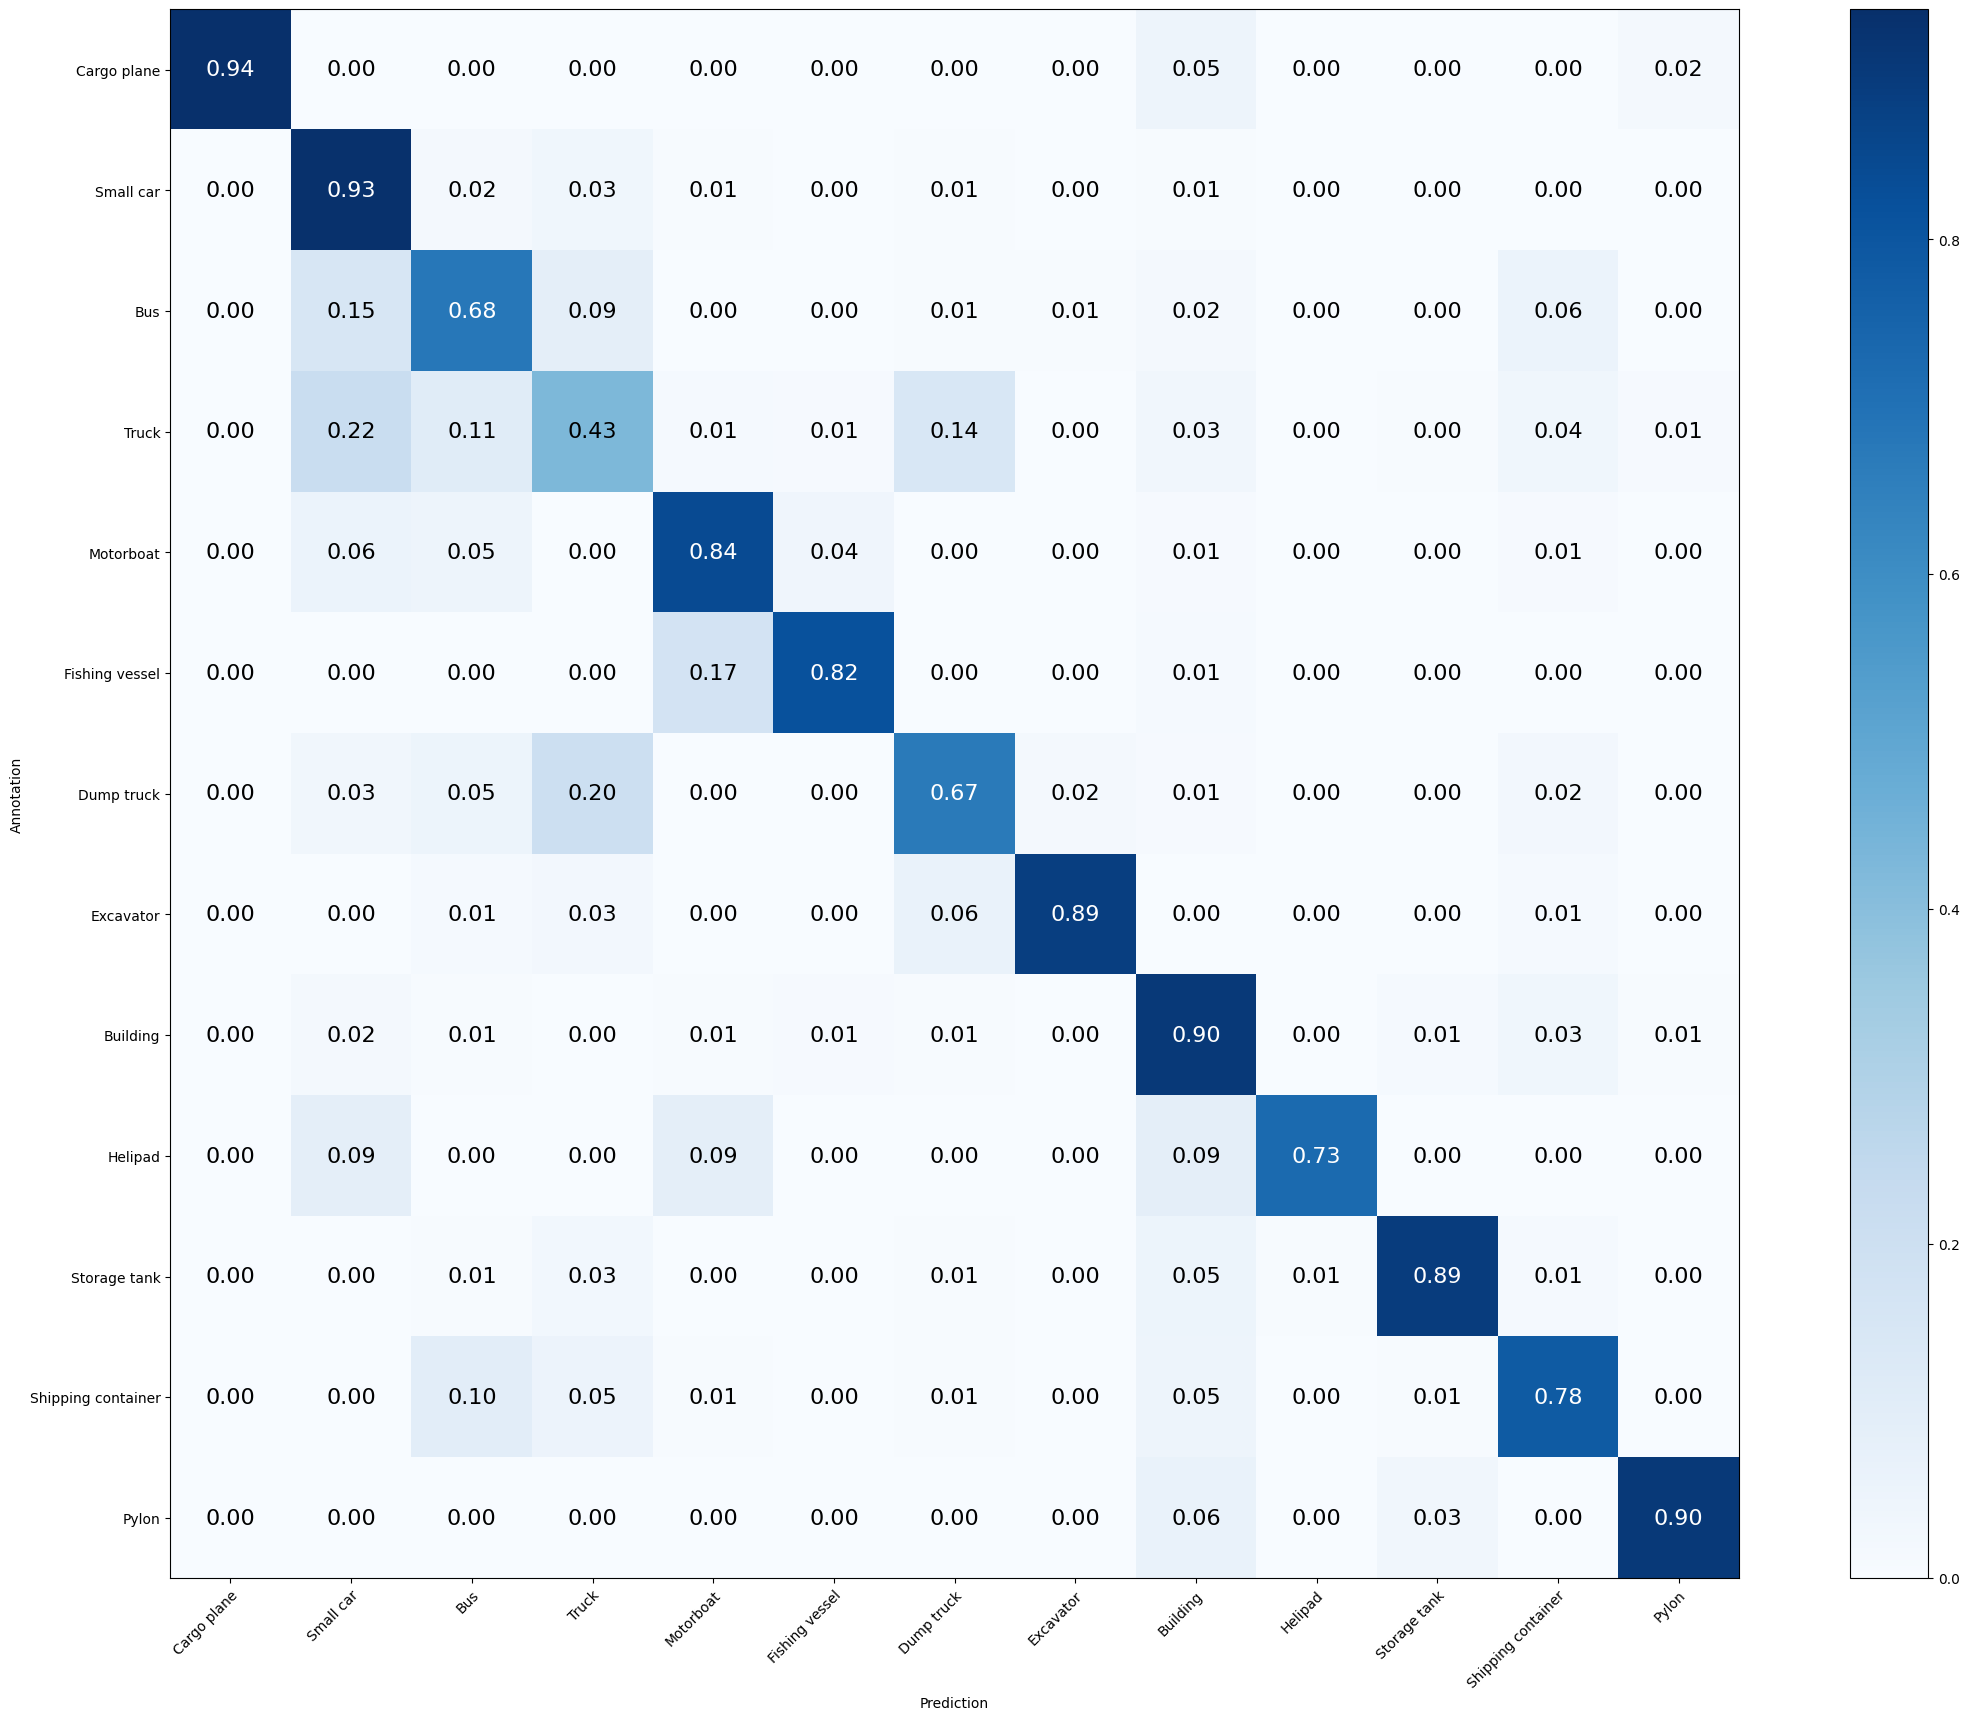

In [18]:
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
draw_confusion_matrix(cm, categories, save_path=os.path.join(run_dir, 'confusion_matrix.png'))

In [19]:
import numpy as np

# Compute the accuracy
correct_samples_class = np.diag(cm).astype(float)
total_samples_class = np.sum(cm, axis=1).astype(float)
total_predicts_class = np.sum(cm, axis=0).astype(float)
print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
print('Mean Recall: %.3f%%' % (acc.mean() * 100))
acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
print('Mean Precision: %.3f%%' % (acc.mean() * 100))
for idx in range(len(categories)):
    # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
    # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
    tp = cm[idx, idx]
    fp = sum(cm[:, idx]) - tp
    fn = sum(cm[idx, :]) - tp
    tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
    # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
    recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
    # Precision: proportion of predicted positive cases that were truly real positives.
    precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
    # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
    specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
    # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
    # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
    f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
    print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 79.680%
Mean Recall: 79.939%
Mean Precision: 81.767%
> Cargo plane: Recall: 93.750% Precision: 100.000% Specificity: 100.000% Dice: 96.774%
> Small car: Recall: 93.072% Precision: 77.250% Specificity: 94.102% Dice: 84.426%
> Bus: Recall: 67.797% Precision: 67.039% Specificity: 96.525% Dice: 67.416%
> Truck: Recall: 42.534% Precision: 58.385% Specificity: 95.949% Dice: 49.215%
> Motorboat: Recall: 84.112% Precision: 81.081% Specificity: 98.812% Dice: 82.569%
> Fishing vessel: Recall: 81.690% Precision: 86.567% Specificity: 99.501% Dice: 84.058%
> Dump truck: Recall: 66.935% Precision: 65.354% Specificity: 97.487% Dice: 66.135%
> Excavator: Recall: 88.608% Precision: 94.595% Specificity: 99.777% Dice: 91.503%
> Building: Recall: 90.251% Precision: 90.251% Specificity: 97.691% Dice: 90.251%
> Helipad: Recall: 72.727% Precision: 88.889% Specificity: 99.946% Dice: 80.000%
> Storage tank: Recall: 89.116% Precision: 94.928% Specificity: 99.595% Dice: 91.930%
> Shipping containe

In [20]:
import csv

# Save run results: config + confusion matrix in the run folder, one summary row in experiments/runs.csv
recall_class = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
precision_class = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
np.savetxt(os.path.join(run_dir, 'confusion_matrix.csv'), cm, fmt='%d', delimiter=',', header=','.join(categories.values()))
with open(os.path.join(run_dir, 'config.json'), 'w', encoding='utf-8') as ofs:
    json.dump({'exp_id': EXP_ID, 'arch': 'own CNN, 5 blocks 32-512', 'resolution': RES, 'batch_size': batch_size, 'epochs': epochs, 'optimizer': optimizer_config, 'loss': model.loss, 'augment': ['rot90', 'shift7'], 'batchnorm': 'before', 'monitor': 'val_accuracy'}, ofs, indent=2, default=str)
summary = {
    'run_id': run_id,
    'exp_id': EXP_ID,
    'params': model.count_params(),
    'epochs_run': len(h.history['loss']),
    'best_epoch': best_idx + 1,
    'train_accuracy': round(float(h.history['accuracy'][best_idx]), 4),
    'val_accuracy': round(float(np.sum(correct_samples_class) / np.sum(total_samples_class)), 4),
    'val_mean_recall': round(float(recall_class.mean()), 4),
    'val_mean_precision': round(float(precision_class.mean()), 4),
    'val_min_recall': round(float(recall_class.min()), 4),
}
runs_file = os.path.join('experiments', 'runs.csv')
write_header = not os.path.exists(runs_file)
with open(runs_file, 'a', newline='', encoding='utf-8') as ofs:
    writer = csv.DictWriter(ofs, fieldnames=list(summary.keys()))
    if write_header:
        writer.writeheader()
    writer.writerow(summary)
print(summary)

{'run_id': 'EXP-043_20261024-010622', 'exp_id': 'EXP-043', 'params': 4724845, 'epochs_run': 88, 'best_epoch': 63, 'train_accuracy': 0.8477, 'val_accuracy': 0.7968, 'val_mean_recall': 0.7994, 'val_mean_precision': 0.8177, 'val_min_recall': 0.4253}


#### Summary of the experiments
The model of delivery 1 comes from phases 0-5 of the sweep (one factor at a time; 3 seeds in the later decisions);
delivery 2 regularises it (BatchNorm, 90° rotations, longer training; 3 seeds per variant); delivery 3 replaces it by a
CNN and compares it with known architectures trained from scratch with the same recipe. Every run is in
`experiments/experiments.csv`, the figures and their interpretation in `hyperparameter_sweep.ipynb`, and the reasoning
with references in `LOGBOOK.md`. Validation results after each step (until delivery 2 the decisions were taken on the
mean recall; from delivery 3 on the accuracy, DEC-019):

In [21]:
import pandas as pd

# Validation results after each step (mean ± std over 3 seeds where available), from experiments/experiments.csv
progress = pd.DataFrame([
    ('1-0', 'baseline: raw pixels, linear model (EXP-001)', '0.282', '0.389'),
    ('1-1', 'Rescaling 1/255, callbacks monitoring mean recall (EXP-003)', '0.382', '0.413'),
    ('1-2', '16x16 input, Dense(256) (EXP-005)', '0.549', '0.600'),
    ('1-3', '4 hidden layers of 256 (EXP-006)', '0.572', '0.604'),
    ('1-4', 'LeakyReLU 0.3 (EXP-007, batch 16)', '0.587 ± 0.004', '0.626 ± 0.008'),
    ('1-5', 'delivery 1: Adam beta_1 0.95, batch 256, lr 1.2e-3 (EXP-010)', '0.578 ± 0.007', '0.616 ± 0.006'),
    ('2-1', 'BatchNorm before the activation, lr 3.6e-3 (EXP-013)', '0.590 ± 0.009', '0.612 ± 0.005'),
    ('2-2', 'random 90-degree rotations, patience 15/6 (EXP-019)', '0.617 ± 0.015', '0.632 ± 0.005'),
    ('2-3', 'delivery 2: longer training, patience 25/8 (EXP-021)', '0.646 ± 0.015', '0.643 ± 0.011'),
    ('3-1', 'own CNN at 32 px, monitor val_accuracy (EXP-040)', '0.785 ± 0.007', '0.779 ± 0.004'),
    ('3-2', 'random shifts of +-2 px (EXP-042)', '0.796 ± 0.013', '0.790 ± 0.003'),
    ('3-3', 'delivery 3: 112 px, 5 blocks, shifts of +-7 px (EXP-043)', '0.804 ± 0.006', '0.799 ± 0.002')
], columns=['delivery-step', 'change kept', 'val mean recall', 'val accuracy'])
progress.style.hide(axis='index')

delivery-step,change kept,val mean recall,val accuracy
1-0,"baseline: raw pixels, linear model (EXP-001)",0.282,0.389
1-1,"Rescaling 1/255, callbacks monitoring mean recall (EXP-003)",0.382,0.413
1-2,"16x16 input, Dense(256) (EXP-005)",0.549,0.600
1-3,4 hidden layers of 256 (EXP-006),0.572,0.604
1-4,"LeakyReLU 0.3 (EXP-007, batch 16)",0.587 ± 0.004,0.626 ± 0.008
1-5,"delivery 1: Adam beta_1 0.95, batch 256, lr 1.2e-3 (EXP-010)",0.578 ± 0.007,0.616 ± 0.006
2-1,"BatchNorm before the activation, lr 3.6e-3 (EXP-013)",0.590 ± 0.009,0.612 ± 0.005
2-2,"random 90-degree rotations, patience 15/6 (EXP-019)",0.617 ± 0.015,0.632 ± 0.005
2-3,"delivery 2: longer training, patience 25/8 (EXP-021)",0.646 ± 0.015,0.643 ± 0.011
3-1,"own CNN at 32 px, monitor val_accuracy (EXP-040)",0.785 ± 0.007,0.779 ± 0.004


In [22]:
import pandas as pd

# Delivery 3: own CNN vs known architectures from scratch, same recipe (112 px, rotations + shifts, no imbalance
# treatment, monitor val_accuracy), 3 seeds each, computed from experiments/experiments.csv (EXP-043..EXP-045).
runs = pd.read_csv('experiments/experiments.csv')
models = {'EXP-043_cnn112': 'own CNN (5 blocks)', 'EXP-045_vgg16_bn': 'VGG16 + BatchNorm', 'EXP-044_resnet50': 'ResNet50',
          'EXP-044_inception_v3': 'InceptionV3', 'EXP-044_vgg16': 'VGG16 (no BatchNorm: collapses in 2 of 3 seeds)'}
runs['variant'] = runs['id'].str.replace(r'_seed\d+$', '', regex=True)
sel = runs[runs['variant'].isin(models)]
fmt = lambda s: '%.3f ± %.3f' % (s.mean(), s.std())
table = sel.groupby('variant').agg(params=('params', 'first'), val_accuracy=('val_acc', fmt),
                                   val_mean_recall=('mean_recall', fmt), seeds=('id', 'size'))
table['params'] = (table['params'] / 1e6).map('{:.1f} M'.format)
table.index = table.index.map(models)
table.loc[list(models.values())]

,params,val_accuracy,val_mean_recall,seeds
variant,,,,
own CNN (5 blocks),4.7 M,0.799 ± 0.002,0.804 ± 0.006,3
VGG16 + BatchNorm,14.7 M,0.805 ± 0.003,0.809 ± 0.007,3
ResNet50,23.6 M,0.800 ± 0.009,0.811 ± 0.001,3
InceptionV3,21.8 M,0.802 ± 0.009,0.818 ± 0.005,3
VGG16 (no BatchNorm: collapses in 2 of 3 seeds),14.7 M,0.378 ± 0.323,0.304 ± 0.394,3


#### Testing
Try to improve the results provided in the competition.

In [23]:
import os
import numpy as np

anns = []
for (dirpath, dirnames, filenames) in os.walk('./xview_recognition/xview_test'):
    for filename in sorted(filenames):
        if not filename.lower().endswith('.tif'):  # skip non-image files, e.g. Windows ':Zone.Identifier' copies (ISS-006)
            continue
        image = GenericImage(dirpath + '/' + filename)
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [24]:
import numpy as np
from xview_data import load_cache, list_test_files

model.load_weights('model.keras')
# Same preprocessing as in training: images cached at the same resolution, Rescaling inside the model
x_test = load_cache('test', RES)
test_index = {f: i for i, f in enumerate(list_test_files())}
probs_test = predict_probs(model, x_test, np.arange(len(x_test)))
predictions_data = {"images": {}, "annotations": {}}
for idx, ann in enumerate(anns):
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    predictions = probs_test[test_index[ann.filename.split('/')[-1]]]
    for obj_pred in ann.objects:
        # Save prediction
        pred_category = list(categories.values())[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data

In [25]:
with open("prediction.json", "w") as outfile:
    json.dump(predictions_data, outfile)